# 1 Dataset Introduction

Financial markets are closely linked: the price of one asset is often affected by movements in stock markets, other commodities, currencies and the wider economy. Gold is a common example. Investors often treat it as a "safe haven" and buy it when stock markets fall or inflation rises, and because it is priced in US dollars it also responds to changes in the dollar's value and in interest rates.

This dataset brings these factors together in one daily record, covering two major US stock indices (the S&P 500 and NASDAQ), five commodities (gold, silver, oil, platinum and palladium), two exchange rates and three US economic indicators. This makes it suitable for studying how the assets relate to one another and for building models that predict a future price, such as gold, from the behaviour of the rest of the market.

## 1.1 Dataset Introduction 

The dataset was retrieved from Kaggle, where it was published by the user franciscogcc under the title "Gold Price Regression". It is a daily time series of financial information for market indices, commodities, economic indicators and foreign exchange rates. The market indices and commodities are represented by the price of the exchange-traded fund (ETF) that tracks each one, rather than by the index or spot price itself. Kaggle does not verify uploaded datasets, so this source should be treated with more caution than a curated repository such as UC Irvine. The dataset can be found at the following URL: 

https://www.kaggle.com/datasets/franciscogcc/financial-data

The dataset contains forty-seven (47) attributes over 3,904 rows, covering trading days from 14 January 2010 to 23 October 2024. The file does not define a target. As the dataset was published for regression on the gold price, gold close is treated as the target, with the remaining forty-six (46) attributes as features. The attributes are defined as the following types:

- <mark>Date</mark>: date Presented as a string in the format YYYY-MM-DD. For example: 2010-01-14.
- <mark>Numerical (Continuous)</mark>: the open, high, low and close prices of sp500, nasdaq, silver, oil, platinum, palladium and gold; the daily range (high-low) of each asset except gold; the exchange rates usd_chf and eur_usd; and the macroeconomic indicators us_rates_%, CPI and GDP (39 attributes in total). Prices and rates can take any real value and have no defined upper limit.
- <mark>Numerical (Discrete)</mark>: sp500 volume, nasdaq volume, silver volume, oil volume, platinum volume, palladium volume, gold volume. Volumes are counts of units traded, so they only take whole-number values, although the file stores them as decimals.

There are no categorical attributes. Around 5% of rows are empty apart from the date; these appear to be non-trading days. us_rates_%, CPI and GDP are published monthly or quarterly, so they are present on only around 5%, 5% and 1% of rows respectively. They would need to be forward-filled or removed before modelling. Table 1 summarises the attributes.


**Red Wine Quality**

Herein, the objective of the supervised learning task is to use regression techniques to accurately predict the quality score of a red wine based on features such as its alcohol content, acidity, sulphates and sulphur dioxide levels. This can also be determined from the following:

1) The target variable of quality provides the ground truth, providing real world data that is known to be true, providing an expected outcome for the created model (MathWorks, 2024).
2) quality is a discrete numerical variable taking whole-number values between 0 and 10 (3 to 8 in this dataset), so it is predicted directly as a numerical value. Alternatively, these values could be separated into "good" (quality ≥ 7) and "not good" (quality < 7) during data processing to allow for binary classification.
3) Regression techniques predict numerical values, making them suitable for estimating a wine's quality score.

# Red Wine Quality Dataset – Attributes

| Attribute | Data Type | Variable Type | Description |
|---|---|---|---|
| fixed acidity | float64 | Continuous numerical (input) | Acids that don't evaporate, mainly tartaric (g tartaric acid/dm³). They give the wine its sharpness and structure. |
| volatile acidity | float64 | Continuous numerical (input) | Acids that evaporate, mainly acetic (g acetic acid/dm³). At high levels the wine tastes of vinegar. |
| citric acid | float64 | Continuous numerical (input) | Citric acid content (g/dm³). It adds freshness and flavour. |
| residual sugar | float64 | Continuous numerical (input) | Sugar left after fermentation stops (g/dm³). |
| chlorides | float64 | Continuous numerical (input) | Salt content (g sodium chloride/dm³). |
| free sulfur dioxide | float64 | Continuous numerical (input) | Unbound SO₂ (mg/dm³). It stops microbes and oxidation. |
| total sulfur dioxide | float64 | Continuous numerical (input) | Free plus bound SO₂ (mg/dm³). High levels can be smelled and tasted. |
| density | float64 | Continuous numerical (input) | Density of the wine (g/cm³). It depends mainly on alcohol and sugar content. |
| pH | float64 | Continuous numerical (input) | Acidity on a 0–14 scale, where lower means more acidic. Most wines are between 3 and 4. |
| sulphates | float64 | Continuous numerical (input) | Potassium sulphate (g/dm³), an additive that raises SO₂ levels and helps preserve the wine. |
| alcohol | float64 | Continuous numerical (input) | Alcohol content (% by volume). |
| quality | int64 | Discrete ordinal (target) | The median score given by wine experts, on a 0–10 scale. Only 3–8 appear in this data. |

## 2 Exploratory Data Analysis

With the identification of the dataset, and the supervised learning task being defined as Red Wine Quality and regression respectively, exploratory data analysis (EDA) can be undertaken to facilitate a deeper understanding of the structure of the data, as well as allowing for identification of issues with data quality (IBM, 2024). This is particularly important for this dataset, as although it contains no missing values, 240 rows are exact duplicates, and the target is heavily imbalanced towards average scores of 5 and 6. Furthermore, by creating visualisations of the dataset, it is easier to identify any patterns, trends, or correlations between the chemical properties of a wine and its quality. With conclusions drawn from this exploration, suitable machine learning algorithms and models can be identified, and features can be engineered to improve the performance of the chosen model(s). These model(s) can then be evaluated for their efficacy when provided data of a similar format to the original dataset.

Within the following section, questions and assumptions about the dataset will be proposed. Then an explanation of how data will be split into training, validation, and testing sets will be provided; the split will be stratified on quality so that the rare very low and very high scores appear in every set. This will be followed by EDA, defining the process and results, which will then be measured against the previously proposed questions and assumptions.

### 2.1 Question(s) identification

Research questions should allow the researcher or investigator to set out what they want to know as a hypothesis, regardless of whether the result support the hypothesis or not (Mayo et al., 2013). By providing well posed questions and assumptions the EDA process will be able to support or reject their claims (Lane, 2018). Table 2 below provides several questions related to the dataset and their associated assumptions.

| ID | Question | Assumption |
|---|---|---|
| RQ1 | Does alcohol content impact wine quality? | It is expected that wines with a higher alcohol content will receive higher quality scores, as alcohol contributes to the body and flavour of a wine. |
| RQ2 | Does volatile acidity impact wine quality? | Volatile acidity is mainly acetic acid, which gives an unpleasant vinegar taste at high levels. It is expected that higher volatile acidity will result in lower quality scores. |
| RQ3 | Do sulphates impact wine quality? | Sulphates contribute to sulphur dioxide levels, which protect wine from spoiling. It is expected that moderate increases in sulphates will be associated with higher quality, as the wine is better preserved. |
| RQ4 | Does citric acid impact wine quality? | Citric acid adds freshness to wine, so it is expected that wines with higher citric acid will receive slightly higher quality scores. |
| RQ5 | Does residual sugar impact wine quality? | As the dataset contains red wines, which are generally dry with little sugar remaining, it is expected that residual sugar will have little impact on quality. |
| RQ6 | Are any of the chemical properties closely related to each other? | It is expected that some features will be strongly correlated, such as free and total sulfur dioxide (as free is part of total), fixed acidity and pH, and density and alcohol. Such pairs may carry duplicate information. |

Table 2: Questions and Assumptions

In [2]:
import pandas as pd
import random as rand
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mglearn
from scipy.stats import randint, uniform

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import (train_test_split, KFold, learning_curve,
                                     validation_curve, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score)

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, roc_auc_score)

In [3]:
DATA_PATH = "../datasets/"
wine_qual = pd.read_csv(DATA_PATH + "winequality-red.csv")
print(wine_qual.shape)
wine_qual.head()

(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


#### Check for missing values

In [76]:
wine_qual.isnull().sum()
X = wine_qual.drop(columns="quality")
y = wine_qual["quality"]


In [77]:
# Split off 60% training data & 40% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=42)

# Split the temporary data in half: 20% validation, 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print(len(X_train), len(X_val), len(X_test))

959 320 320


In [78]:
# Print column names, non-null value count, and data types to system output
wine_qual.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [79]:
unique_values = wine_qual['fixed acidity'].unique()
print(unique_values)

[ 7.4  7.8 11.2  7.9  7.3  7.5  6.7  5.6  8.9  8.5  8.1  7.6  6.9  6.3
  7.1  8.3  5.2  5.7  8.8  6.8  4.6  7.7  8.7  6.4  6.6  8.6 10.2  7.
  7.2  9.3  8.   9.7  6.2  5.   4.7  8.4 10.1  9.4  9.   8.2  6.1  5.8
  9.2 11.5  5.4  9.6 12.8 11.  11.6 12.  15.  10.8 11.1 10.  12.5 11.8
 10.9 10.3 11.4  9.9 10.4 13.3 10.6  9.8 13.4 10.7 11.9 12.4 12.2 13.8
  9.1 13.5 10.5 12.6 14.  13.7  9.5 12.7 12.3 15.6  5.3 11.3 13.   6.5
 12.9 14.3 15.5 11.7 13.2 15.9 12.1  5.1  4.9  5.9  6.   5.5]


In [80]:
wine_qual.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


## Univariate Analysis

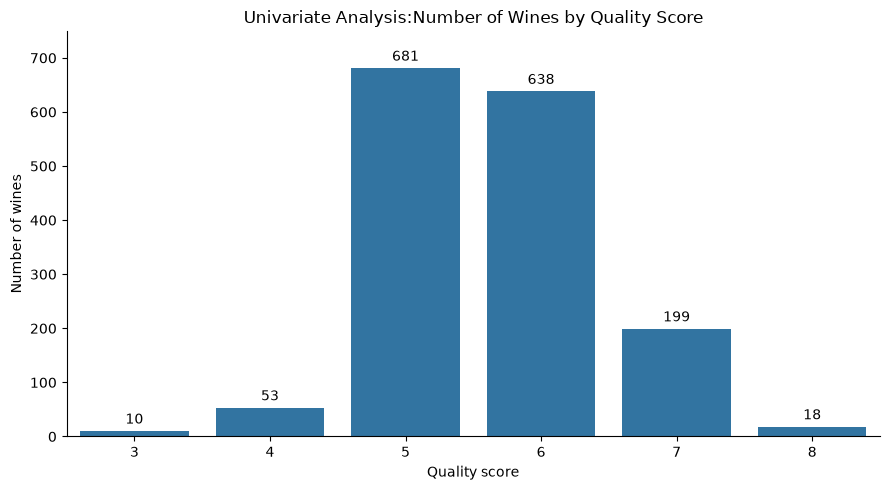

In [81]:
# Number of wines for each quality score
plt.figure(figsize=(9,5))
# Set x axis as quality
quality_plot = sns.countplot(x=wine_qual["quality"])

# Put the count above each bar
quality_plot.bar_label(quality_plot.containers[0], padding=3)

# Title the plot
quality_plot.set_title("Univariate Analysis:Number of Wines by Quality Score")
quality_plot.set_xlabel("Quality score")
quality_plot.set_ylabel("Number of wines")
quality_plot.margins(y=0.1) # leave room above the tallest bar for its label
sns.despine()

plt.tight_layout()
plt.show()

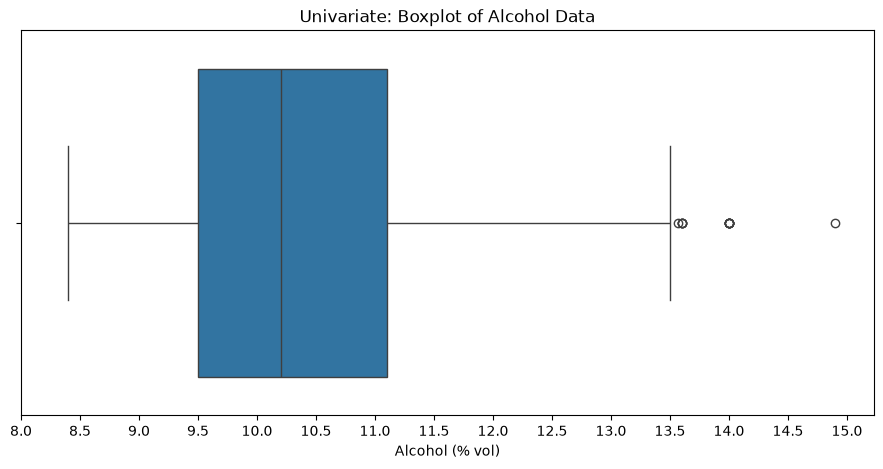

In [82]:
plt.figure(figsize=(11,5))

# Set x axis as temp
sns.boxplot(x = wine_qual["alcohol"])

# Title the plot
plt.title("Univariate: Boxplot of Alcohol Data")
# Label the axis
plt.xlabel("Alcohol (% vol)")

# Get the minimum and maximum values for temp column for use with numpy
min_alc = np.floor(wine_qual["alcohol"]).min()
max_alc = np.ceil(wine_qual["alcohol"]).max()

# Add ticks on x axis for more accurate value reading
plt.xticks(np.arange(min_alc, max_alc + 0.5, 0.5))

# Show the plot
plt.show()

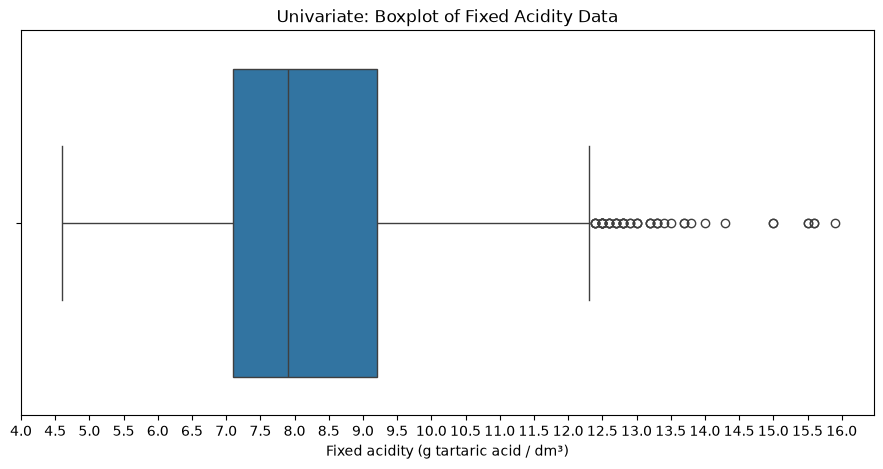

In [83]:
plt.figure(figsize=(11,5))

# Set x axis as temp
sns.boxplot(x = wine_qual["fixed acidity"])

# Title the plot
plt.title("Univariate: Boxplot of Fixed Acidity Data")
# Label the axis
plt.xlabel("Fixed acidity (g tartaric acid / dm³)")

# Get the minimum and maximum values for temp column for use with numpy
min_fa = np.floor(wine_qual["fixed acidity"]).min()
max_fa = np.ceil(wine_qual["fixed acidity"]).max()

# Add ticks on x axis for more accurate value reading
plt.xticks(np.arange(min_fa, max_fa + 0.5, 0.5))

# Show the plot
plt.show()

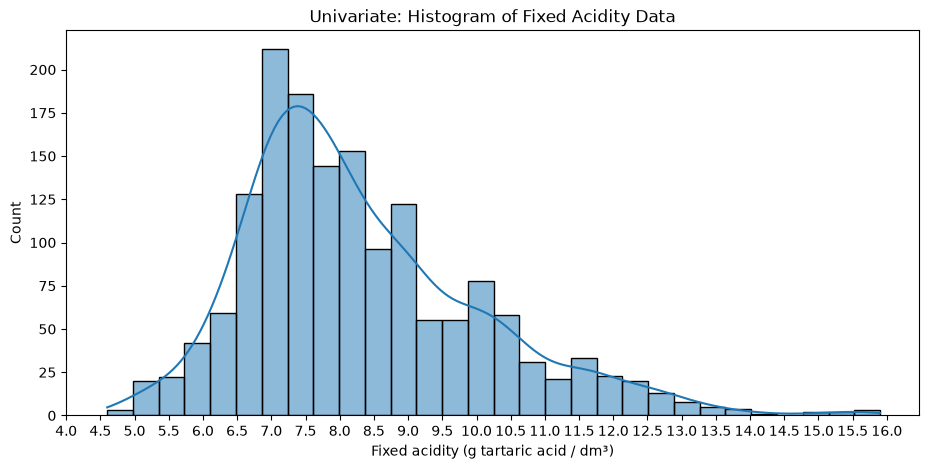

In [84]:
plt.figure(figsize=(11,5))

# Set x axis as temp
sns.histplot(wine_qual["fixed acidity"], kde=True, bins=30)

# Title the plot
plt.title("Univariate: Histogram of Fixed Acidity Data")
# Label the axis
plt.xlabel("Fixed acidity (g tartaric acid / dm³)")

# Get the minimum and maximum values for temp column for use with numpy
min_fa = np.floor(wine_qual["fixed acidity"]).min()
max_fa = np.ceil(wine_qual["fixed acidity"]).max()

# Add ticks on x axis for more accurate value reading
plt.xticks(np.arange(min_fa, max_fa + 0.5, 0.5))

# Show the plot
plt.show()

## Bivariate Analysis

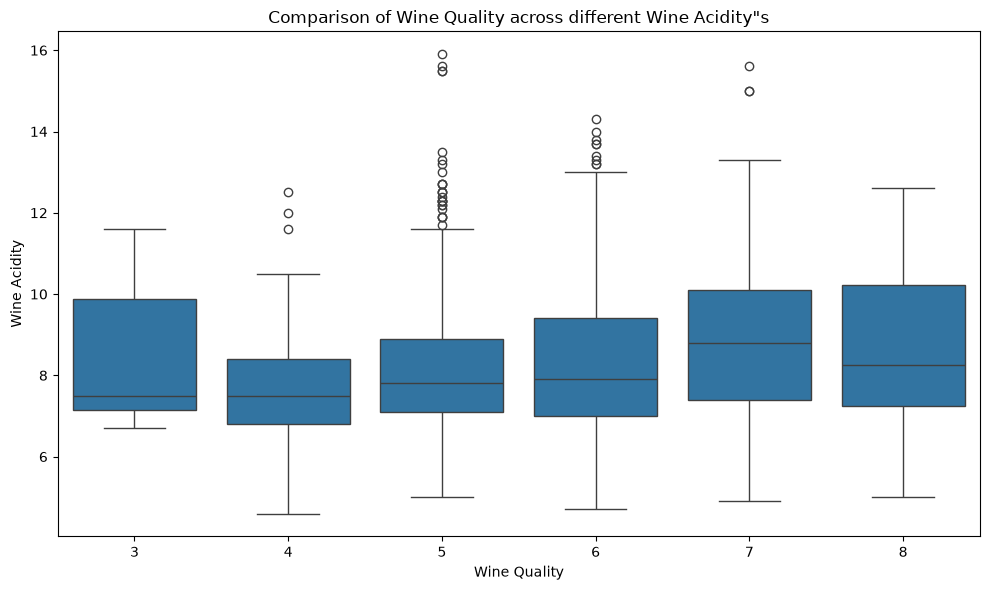

In [85]:
plt.figure(figsize=(10,6))
sns.boxplot(x=wine_qual["quality"], y= wine_qual["fixed acidity"])

# Title the plot
plt.title('Comparison of Wine Quality across different Wine Acidity"s')

# Label the axis
plt.xlabel("Wine Quality")
plt.ylabel("Wine Acidity")

# Show the plot
plt.tight_layout()
plt.show()

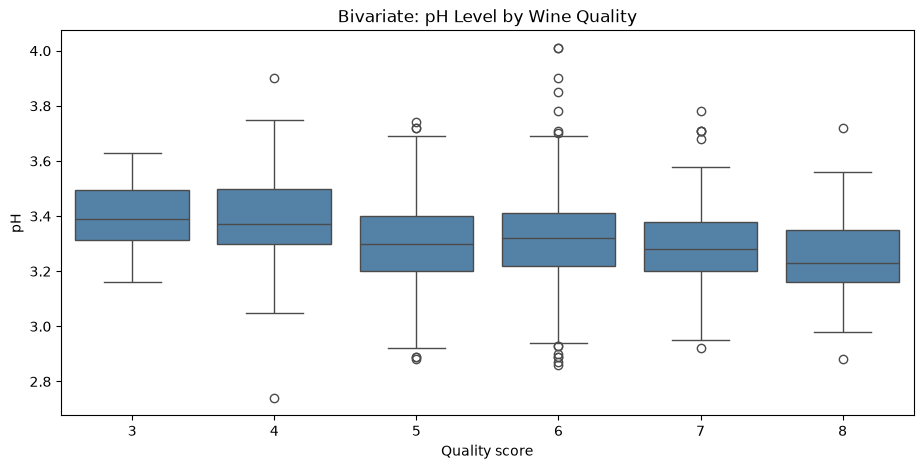

         count  median  mean
quality                     
3           10    3.39  3.40
4           53    3.37  3.38
5          681    3.30  3.30
6          638    3.32  3.32
7          199    3.28  3.29
8           18    3.23  3.27
Correlation: -0.058


In [86]:
# Filter wine quality column to only required rows
required_scores = [4, 5, 6, 7]          # change to the scores you want to keep
wine_filtered = wine_qual[wine_qual["quality"].isin(required_scores)]

# Compare the Wine Quality across different ph levels
plt.figure(figsize=(11, 5))

# One box of pH values for each quality score
sns.boxplot(x=wine_qual["quality"], y=wine_qual["pH"], color="steelblue")

# Title and axis labels
plt.title("Bivariate: pH Level by Wine Quality")
plt.xlabel("Quality score")
plt.ylabel("pH")

plt.show()

# Number of wines and average pH for each quality score
print(wine_qual.groupby("quality")["pH"].agg(["count", "median", "mean"]).round(2))

# Correlation between pH and quality
print("Correlation:", round(wine_qual["pH"].corr(wine_qual["quality"]), 3))


In [87]:
# Group the filtered group description for wine quality
wine_filtered.groupby("quality")["pH"].describe()

,count,mean,std,min,25%,50%,75%,max
quality,,,,,,,,
4,53.0,3.381509,0.181441,2.74,3.30,3.37,3.50,3.90
5,681.0,3.304949,0.150618,2.88,3.20,3.30,3.40,3.74
6,638.0,3.318072,0.153995,2.86,3.22,3.32,3.41,4.01
7,199.0,3.290754,0.150101,2.92,3.20,3.28,3.38,3.78


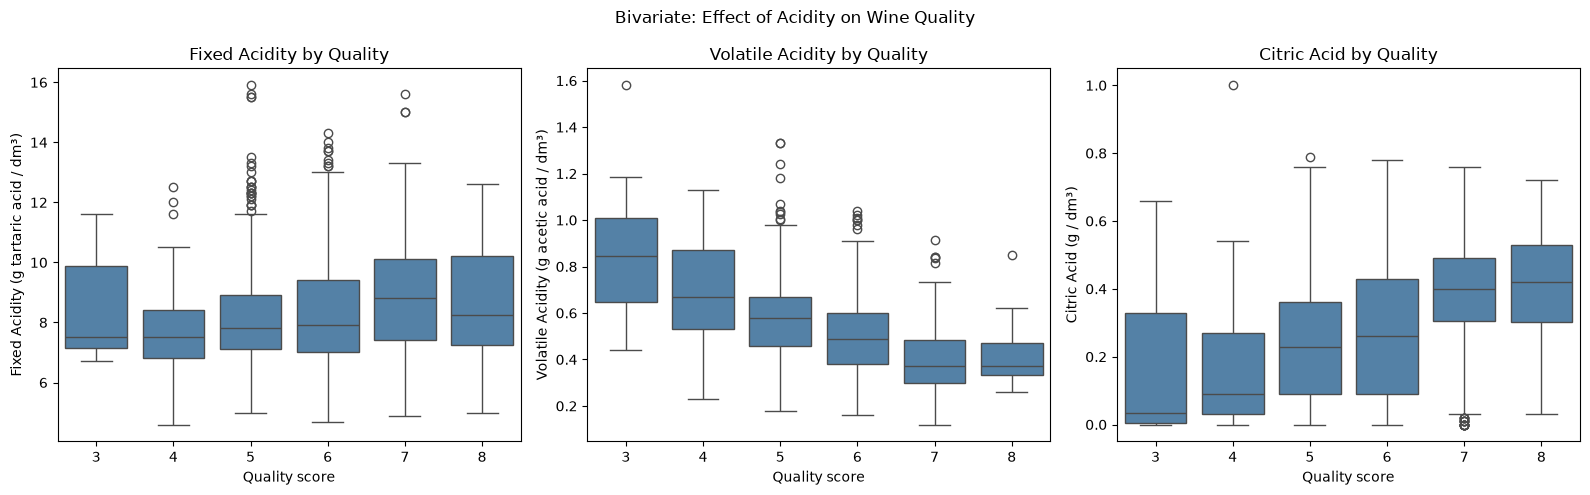

         fixed acidity  volatile acidity  citric acid
quality                                              
3                 7.50              0.84         0.04
4                 7.50              0.67         0.09
5                 7.80              0.58         0.23
6                 7.90              0.49         0.26
7                 8.80              0.37         0.40
8                 8.25              0.37         0.42
fixed acidity       0.124
volatile acidity   -0.391
citric acid         0.226
dtype: float64


In [88]:
# Effect of acidity on the wine quality
acidity_cols = ["fixed acidity", "volatile acidity", "citric acid"]
units = ["g tartaric acid / dm³", "g acetic acid / dm³", "g / dm³"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# One box plot per acidity column, with a box for each quality score
for ax, col, unit in zip(axes, acidity_cols, units):
    sns.boxplot(x=wine_qual["quality"], y=wine_qual[col], color="steelblue", ax=ax)
    ax.set_title(f"{col.title()} by Quality")
    ax.set_xlabel("Quality score")
    ax.set_ylabel(f"{col.title()} ({unit})")

plt.suptitle("Bivariate: Effect of Acidity on Wine Quality")
plt.tight_layout()
plt.show()

# Median of each acidity measure for each quality score
print(wine_qual.groupby("quality")[acidity_cols].median().round(2))

# Correlation of each acidity measure with quality
print(wine_qual[acidity_cols].corrwith(wine_qual["quality"]).round(3))

## Multivariate Analysis

### Numerical Multivariate Analysis

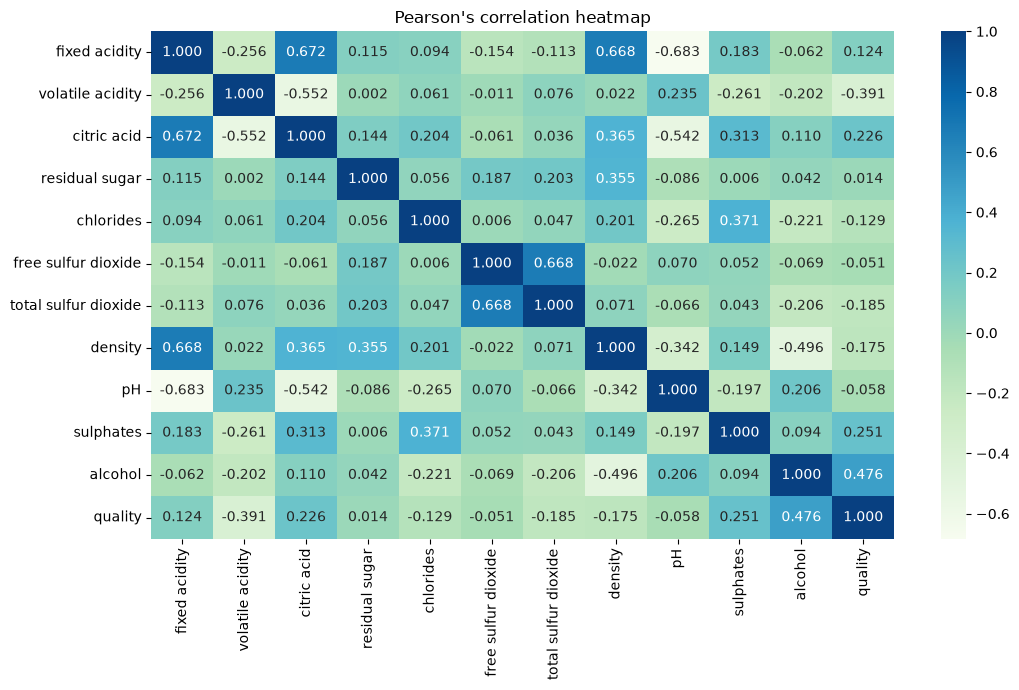

In [89]:
# Numerical Multivariate Analysis
# Correlation matrix numerical start
# Pearson correlation

corr = wine_qual.corr(method="pearson")


mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 7))

sns.heatmap(corr, annot=True, cmap="GnBu", fmt=".3f")

# Title the plot
plt.title("Pearson's correlation heatmap")

# Show the plot
plt.tight_layout()
plt.show()

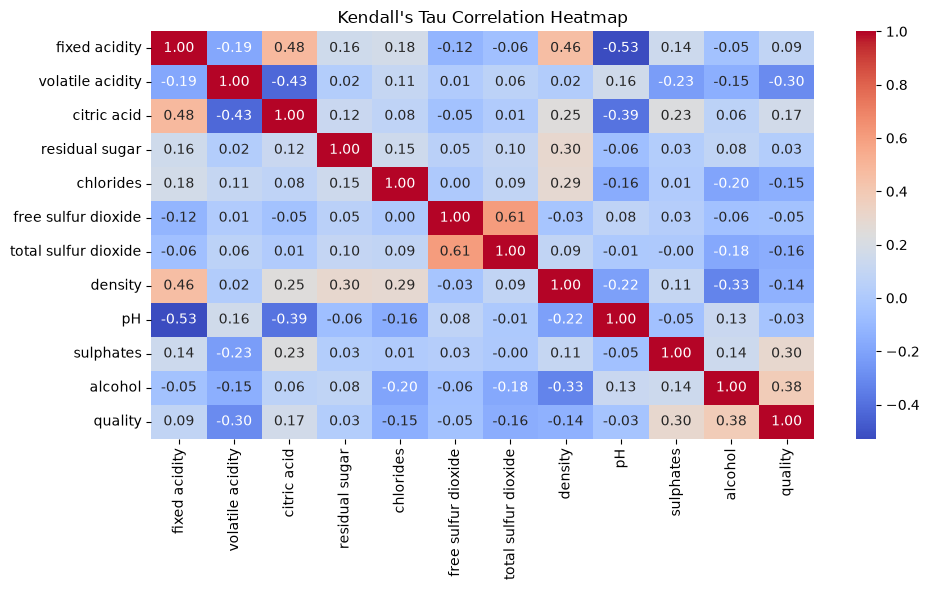

In [90]:
kendall_corr = wine_qual.corr(method="kendall")

plt.figure(figsize=(10,6))

# Build heatmap
sns.heatmap(kendall_corr, annot=True, cmap="coolwarm", fmt=".2f")

# Title of the plat
plt.title("Kendall's Tau Correlation Heatmap")

plt.tight_layout()
plt.show()

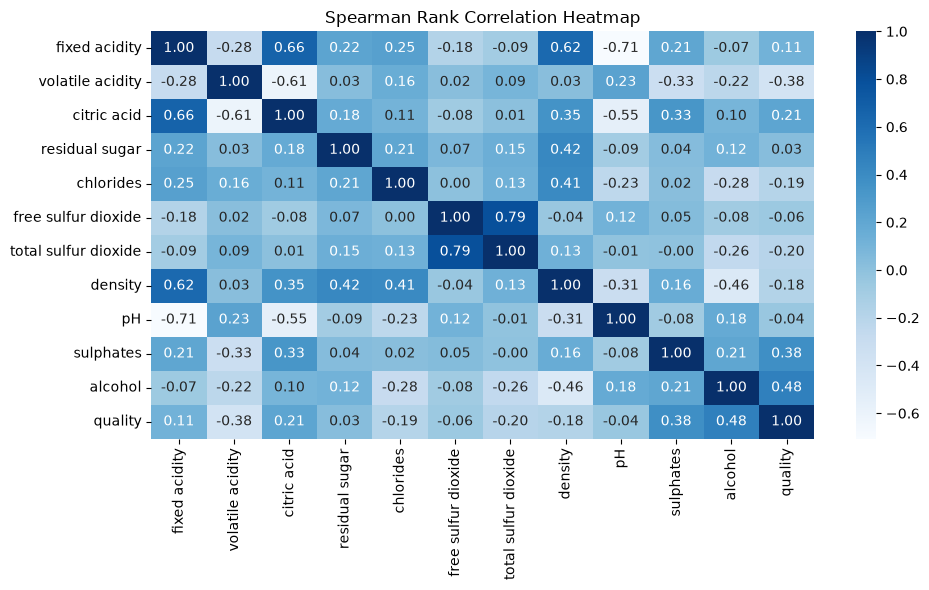

In [91]:
# Spearman Rank Correlation Heatmap

spearman_corr = wine_qual.corr(method="spearman")

plt.figure(figsize=(10, 6))

# Build Heatmap
sns.heatmap(spearman_corr, annot=True, cmap="Blues", fmt=".2f")

# Title the plot
plt.title("Spearman Rank Correlation Heatmap")

plt.tight_layout()
plt.show()

# 3. Experimental Design

In [92]:
# Prepare the dataset
wine_qual_pre_process = wine_qual.copy(deep=True)

# Remove duplicate rows
# 240 rows are exact copies; left in, the same wine could appear in both training and test sets
print("Duplicates:", wine_qual_pre_process.duplicated().sum())
wine_qual_pre_process = wine_qual_pre_process.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(wine_qual_pre_process))

# Imputation of the feature
# Check for missing values: there are none, so no imputation is needed
print("Missing values:", wine_qual_pre_process.isna().sum().sum())

# If missing values ever appeared, fill each numeric column with its median
# (the median is less affected by the skewed columns than the mean)
# wine_qual_pre_process = wine_qual_pre_process.fillna(wine_qual_pre_process.median())

# Conversion of the feature
# All 11 inputs are already float64 and quality is int64, so no type conversion is needed
print(wine_qual_pre_process.dtypes)

# For classification, convert the numeric quality score into categories
# Option 1: three groups (low = 3-4, medium = 5-6, high = 7-8)
wine_qual_pre_process["quality_label"] = pd.cut(
    wine_qual_pre_process["quality"],
    bins=[0, 4, 6, 10],
    labels=["low", "medium", "high"])

# Option 2: two groups (good = 7 and above)
wine_qual_pre_process["is_good"] = (wine_qual_pre_process["quality"] >= 7).astype(int)

# Encoding the feature
# None of the inputs are text, so they need no encoding
# The quality_label category needs turning into numbers for scikit-learn
# Map the labels by hand so the numbers keep their order (low < medium < high)
quality_mapping = {"low": 0, "medium": 1, "high": 2}
wine_qual_pre_process["quality_label_enc"] = (
    wine_qual_pre_process["quality_label"].map(quality_mapping).astype(int))

print(wine_qual_pre_process["quality_label"].value_counts())
print(wine_qual_pre_process["is_good"].value_counts())

Duplicates: 240
Rows after removing duplicates: 1359
Missing values: 0
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object
quality_label
medium    1112
high       184
low         63
Name: count, dtype: int64
is_good
0    1175
1     184
Name: count, dtype: int64


In [93]:
X = wine_qual_pre_process.drop(columns=["quality", "quality_label", "is_good", "quality_label_enc"])
y = wine_qual_pre_process["quality"]            # regression
# y = wine_qual_pre_process["is_good"]          # 2-group classification
# y = wine_qual_pre_process["quality_label_enc"]  # 3-group classification

#### Linear Regression

In [94]:
lr = LinearRegression().fit(X_train, y_train)
print("Coefficients:")
print(pd.Series(lr.coef_, index=X_train.columns).round(3))
print("Intercept: {:.2f}".format(lr.intercept_))

print("Training set score:   {:.2f}".format(lr.score(X_train, y_train)))
print("Validation set score: {:.2f}".format(lr.score(X_val, y_val)))
print("Test set score:       {:.2f}".format(lr.score(X_test, y_test)))

Coefficients:
fixed acidity          -0.008
volatile acidity       -1.039
citric acid            -0.157
residual sugar         -0.001
chlorides              -2.032
free sulfur dioxide     0.004
total sulfur dioxide   -0.004
density                 5.111
pH                     -0.558
sulphates               0.756
alcohol                 0.288
dtype: float64
Intercept: -0.16
Training set score:   0.35
Validation set score: 0.39
Test set score:       0.36


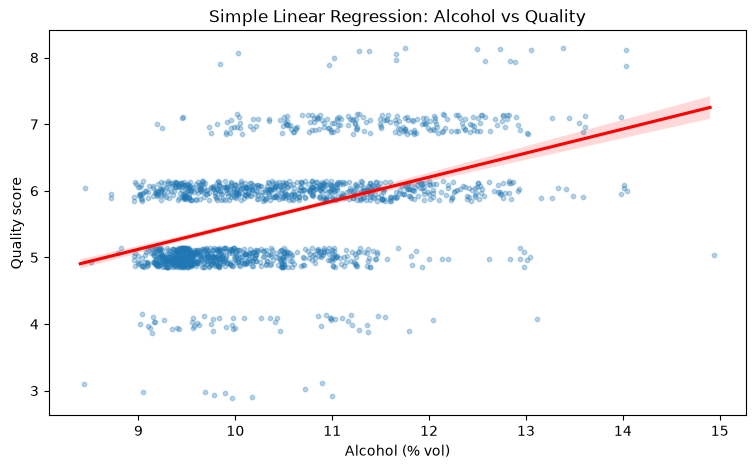

In [95]:
plt.figure(figsize=(9, 5))

# Scatter plot plus fitted line; the jitter spreads out wines with the same values
sns.regplot(x=wine_qual["alcohol"], y=wine_qual["quality"],
            x_jitter=0.05, y_jitter=0.15,
            scatter_kws={"s": 10, "alpha": 0.3}, line_kws={"color": "red"})

plt.title("Simple Linear Regression: Alcohol vs Quality")
plt.xlabel("Alcohol (% vol)")
plt.ylabel("Quality score")
plt.show()

#### K Nearest Neighbours Regression

Best k: 48


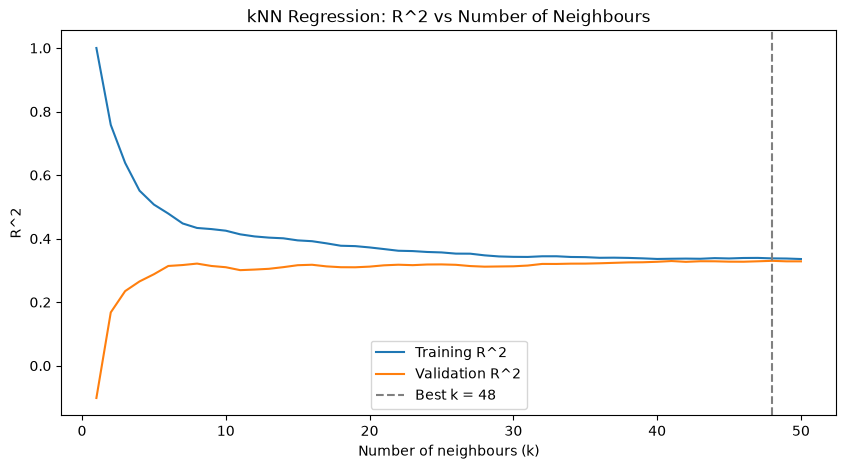

Training set score:   0.34
Validation set score: 0.33
Test set score:       0.33
Test MAE:             0.536


In [96]:
# Scale the features

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# Try k = 1 to 50 and score each on the validation set
k_values = range(1, 51)
train_scores, val_scores = [], []
for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k).fit(X_train_s, y_train)
    train_scores.append(knn.score(X_train_s, y_train))
    val_scores.append(knn.score(X_val_s, y_val))

best_k = k_values[int(np.argmax(val_scores))]
print("Best k:", best_k)

# Plot training and validation R^2 against K

plt.figure(figsize=(10, 5))
plt.plot(k_values, train_scores, label="Training R^2")
plt.plot(k_values, val_scores, label="Validation R^2")
plt.axvline(best_k, color="grey", linestyle="--", label=f"Best k = {best_k}")
plt.xlabel("Number of neighbours (k)")
plt.ylabel("R^2")
plt.title("kNN Regression: R^2 vs Number of Neighbours")
plt.legend()
plt.show()

# Final model with the best k, scored once on the test set
knn = KNeighborsRegressor(n_neighbors=best_k).fit(X_train_s, y_train)
print("Training set score:   {:.2f}".format(knn.score(X_train_s, y_train)))
print("Validation set score: {:.2f}".format(knn.score(X_val_s, y_val)))
print("Test set score:       {:.2f}".format(knn.score(X_test_s, y_test)))
print("Test MAE:             {:.3f}".format(mean_absolute_error(y_test, knn.predict(X_test_s))))

#### Decision Tree

Default tree - depth: 17 leaves: 259
Training set score:   1.00
Validation set score: -0.17


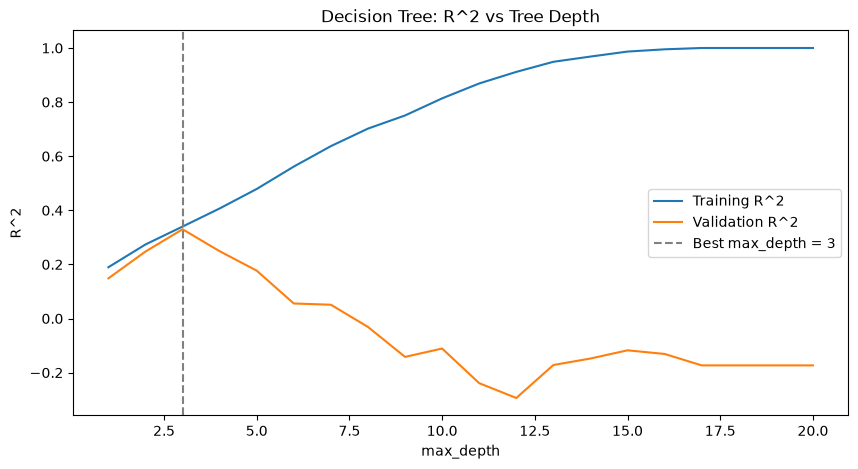

Training set score:   0.34
Validation set score: 0.33
Test set score:       0.28
Test MAE:             0.527


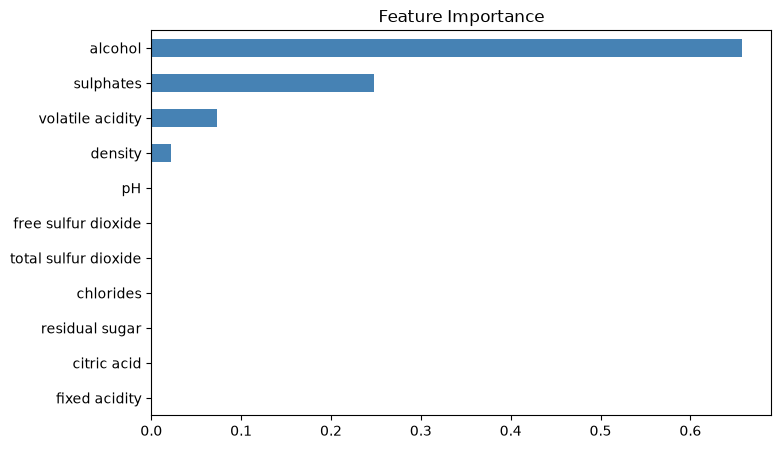

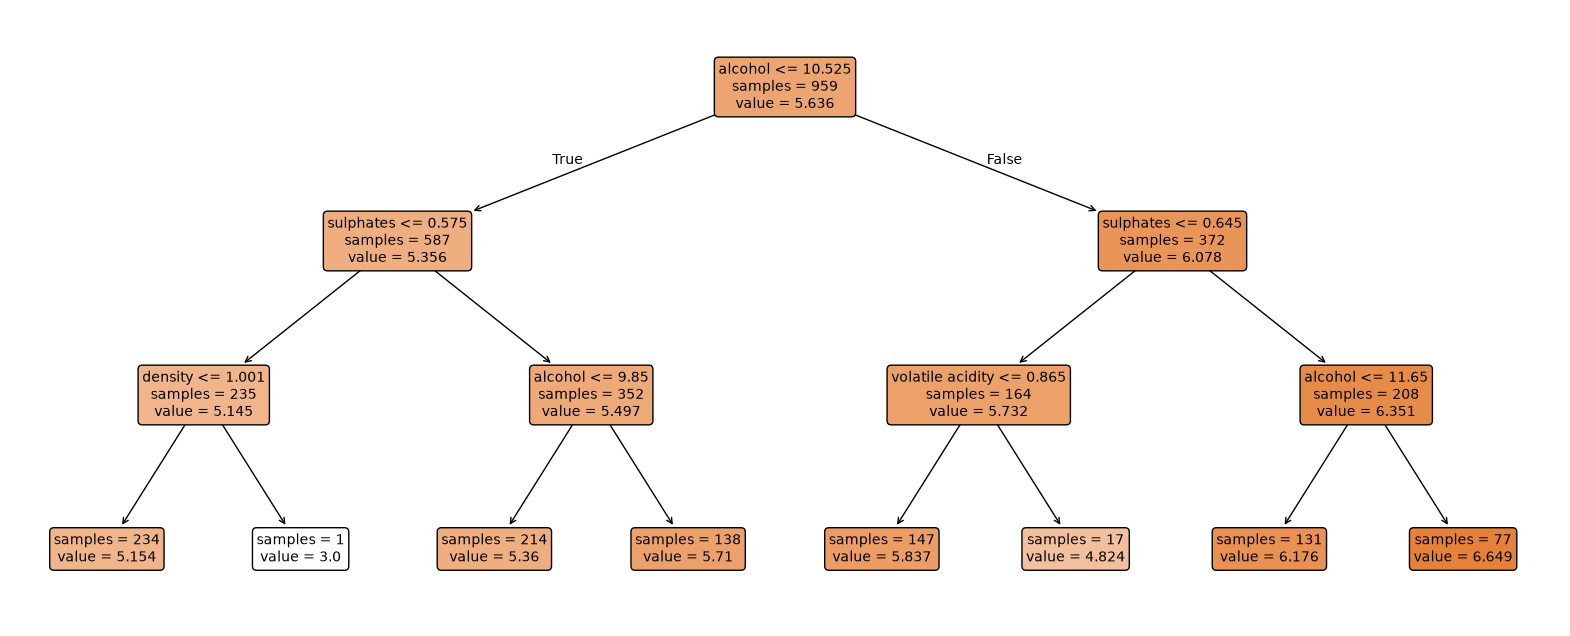

In [97]:
# Default tree with no depth limit
tree = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)
print("Default tree - depth:", tree.get_depth(), "leaves:", tree.get_n_leaves())
print("Training set score:   {:.2f}".format(tree.score(X_train, y_train)))
print("Validation set score: {:.2f}".format(tree.score(X_val, y_val)))

# Try max_depth from 1 to 20 and score each on the validation set
depths = range(1, 21)
train_scores, val_scores = [], []
for d in depths:
    d_tree = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train, y_train)
    train_scores.append(d_tree.score(X_train, y_train))
    val_scores.append(d_tree.score(X_val, y_val))
    
best_depth = depths[int(np.argmax(val_scores))]

plt.figure(figsize=(10, 5))
plt.plot(depths, train_scores, label="Training R^2")
plt.plot(depths, val_scores, label="Validation R^2")
plt.axvline(best_depth, color="grey", linestyle="--", label=f"Best max_depth = {best_depth}")
plt.xlabel("max_depth")
plt.ylabel("R^2")
plt.title("Decision Tree: R^2 vs Tree Depth")
plt.legend()
plt.show()

# Final tree with the best depth, scored once on the test set
tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42).fit(X_train, y_train)
print("Training set score:   {:.2f}".format(tree.score(X_train, y_train)))
print("Validation set score: {:.2f}".format(tree.score(X_val, y_val)))
print("Test set score:       {:.2f}".format(tree.score(X_test, y_test)))
print("Test MAE:             {:.3f}".format(mean_absolute_error(y_test, tree.predict(X_test))))

# 4. Feature importance: how much each feature contributes to the tree's splits
importance = pd.Series(tree.feature_importances_, index=X_train.columns).sort_values()
importance.plot.barh(figsize=(8, 5), color="steelblue", title="Feature Importance")
plt.show()

# 5. Draw the tree
plt.figure(figsize=(20, 8))
plot_tree(tree, feature_names=list(X_train.columns), filled=True,
          rounded=True, fontsize=10, impurity=False)
plt.show()

#### Random Forest

Default - Training: 0.92  Validation: 0.42
    max_depth  min_samples_leaf max_features  train_R2  val_R2
5         NaN                 3          0.5     0.806   0.437
41       12.0                 3          0.5     0.798   0.435
39       12.0                 3          1.0     0.816   0.435
3         NaN                 3          1.0     0.822   0.433
6         NaN                 5          1.0     0.742   0.432
Training set score:   0.90
Validation set score: 0.42
Test set score:       0.47
Test MAE:  0.442
Test RMSE: 0.584


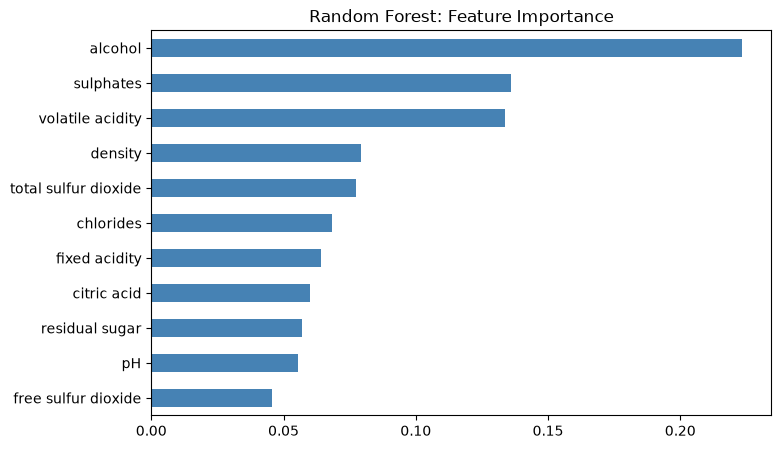

In [98]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Like a single tree, a random forest doesn't need feature scaling

# 1. Default forest
rf = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1).fit(X_train, y_train)
print("Default - Training: {:.2f}  Validation: {:.2f}".format(
    rf.score(X_train, y_train), rf.score(X_val, y_val)))

# 2. Try combinations of settings and score each on the validation set
results = []
for max_depth in [None, 5, 8, 12]:
    for min_leaf in [1, 3, 5, 10]:
        for max_feat in [1.0, "sqrt", 0.5]:
            m = RandomForestRegressor(n_estimators=500, max_depth=max_depth,
                                      min_samples_leaf=min_leaf, max_features=max_feat,
                                      random_state=42, n_jobs=-1).fit(X_train, y_train)
            results.append({"max_depth": max_depth, "min_samples_leaf": min_leaf,
                            "max_features": max_feat,
                            "train_R2": m.score(X_train, y_train),
                            "val_R2": m.score(X_val, y_val)})

results = pd.DataFrame(results).sort_values("val_R2", ascending=False)
print(results.head().round(3))

# 3. Final forest with the best settings, scored once on the test set
rf = RandomForestRegressor(n_estimators=500, max_depth=12, min_samples_leaf=1,
                           max_features=0.5, random_state=42, n_jobs=-1).fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print("Training set score:   {:.2f}".format(rf.score(X_train, y_train)))
print("Validation set score: {:.2f}".format(rf.score(X_val, y_val)))
print("Test set score:       {:.2f}".format(rf.score(X_test, y_test)))
print("Test MAE:  {:.3f}".format(mean_absolute_error(y_test, y_pred_rf)))
print("Test RMSE: {:.3f}".format(mean_squared_error(y_test, y_pred_rf) ** 0.5))

# 4. Feature importance
importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
importance.plot.barh(figsize=(8, 5), color="steelblue", title="Random Forest: Feature Importance")
plt.show()

#### Multi Linear Regression

Training set score:   0.35
Validation set score: 0.39
Test set score:       0.36
Test MAE:  0.506
Test RMSE: 0.644


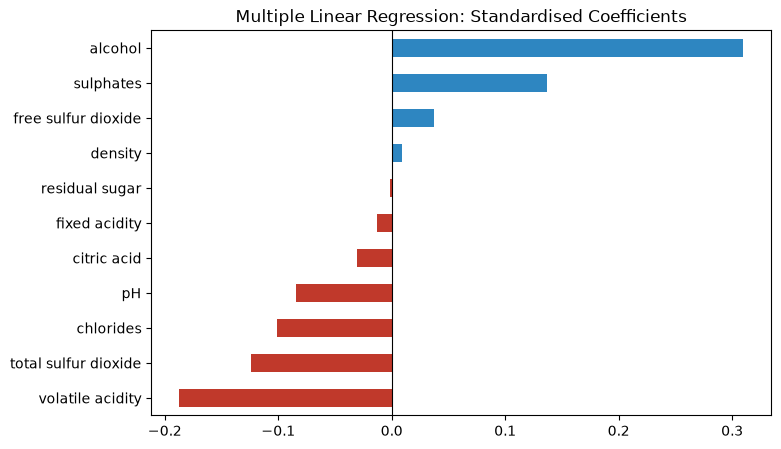

In [99]:
from sklearn.preprocessing import StandardScaler

# Standardise the features (fit on training data only) so the coefficients can be compared
scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (scaler.transform(X_train),
                                scaler.transform(X_val),
                                scaler.transform(X_test))

mlr = LinearRegression().fit(X_train_s, y_train)
y_pred_mlr = mlr.predict(X_test_s)

print("Training set score:   {:.2f}".format(mlr.score(X_train_s, y_train)))
print("Validation set score: {:.2f}".format(mlr.score(X_val_s, y_val)))
print("Test set score:       {:.2f}".format(mlr.score(X_test_s, y_test)))
print("Test MAE:  {:.3f}".format(mean_absolute_error(y_test, y_pred_mlr)))
print("Test RMSE: {:.3f}".format(mean_squared_error(y_test, y_pred_mlr) ** 0.5))

# Standardised coefficients: change in quality when a feature rises by 1 standard deviation
coefs = pd.Series(mlr.coef_, index=X_train.columns).sort_values()
colours = ["#c0392b" if c < 0 else "#2e86c1" for c in coefs]
coefs.plot.barh(figsize=(8, 5), color=colours,
                title="Multiple Linear Regression: Standardised Coefficients")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

In [100]:
for col in X_train.columns:
    others = X_train.drop(columns=col)
    r2 = LinearRegression().fit(others, X_train[col]).score(others, X_train[col])
    print(f"{col:22s} VIF = {1 / (1 - r2):.2f}")

fixed acidity          VIF = 7.65
volatile acidity       VIF = 1.84
citric acid            VIF = 3.24
residual sugar         VIF = 1.67
chlorides              VIF = 1.52
free sulfur dioxide    VIF = 1.91
total sulfur dioxide   VIF = 2.22
density                VIF = 6.25
pH                     VIF = 3.28
sulphates              VIF = 1.50
alcohol                VIF = 3.18


## Predictive Modelling / Model Development

## Training the model

In [101]:
 # Tuned settings from the hyperparameter search
BEST_PARAMS = dict(max_depth=8, max_features=0.5, min_samples_leaf=4)

rf = RandomForestRegressor(warm_start=True, oob_score=True, random_state=42, n_jobs=-1)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
history = []

for n_trees in range(20, 501, 10):
    rf.set_params(n_estimators = n_trees)
    rf.fit(X_train, y_train)
    history.append({
        "trees": n_trees,
        "train_mse": mean_squared_error(y_train, rf.predict(X_train)),
        "oob_mse": mean_squared_error(y_train, rf.oob_prediction_),
        "val_mse": mean_squared_error(y_val, rf.predict(X_val)),        
    })
    
history = pd.DataFrame(history)
print(history.iloc[[0, 3, 8, 18, 28, 48]].round(4).to_string(index=False))

 trees  train_mse  oob_mse  val_mse
    20     0.0654   0.4240   0.4045
    50     0.0555   0.3847   0.3879
   100     0.0529   0.3789   0.3892
   200     0.0504   0.3684   0.3817
   300     0.0501   0.3666   0.3814
   500     0.0497   0.3627   0.3792


In [102]:
# 8.2 Learning curve: loss as the amount of training data grows

sizes, tr_scores, cv_scores = learning_curve(
    RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 8), cv=kf,
    scoring="neg_mean_squared_error", n_jobs=-1)
lc = pd.DataFrame({"train_size": sizes,
                   "train_mse": -tr_scores.mean(axis=1),
                   "cv_mse": -cv_scores.mean(axis=1),
                   "cv_std": cv_scores.std(axis=1)})
print(lc.round(4).to_string(index=False))

 train_size  train_mse  cv_mse  cv_std
         76     0.0668  0.5154  0.0564
        175     0.0618  0.4442  0.0555
        273     0.0620  0.4265  0.0454
        372     0.0573  0.4185  0.0534
        471     0.0561  0.3968  0.0499
        569     0.0544  0.3926  0.0506
        668     0.0517  0.3849  0.0502
        767     0.0513  0.3744  0.0539


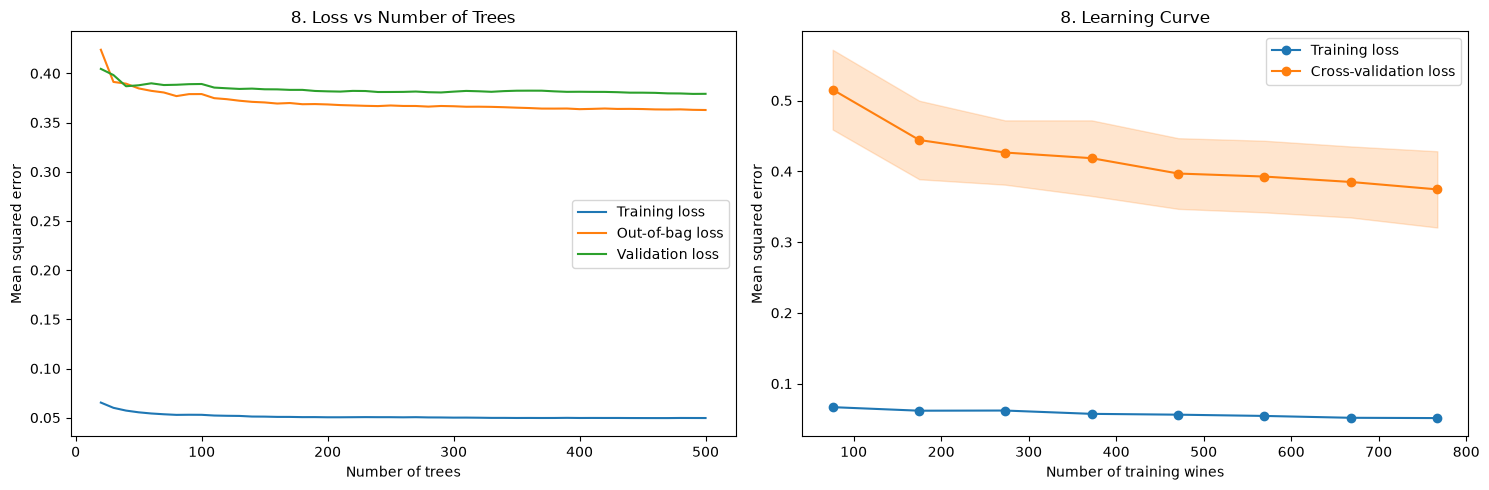

In [103]:
# %% 8.3 Plot the training curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(history["trees"], history["train_mse"], label="Training loss")
axes[0].plot(history["trees"], history["oob_mse"], label="Out-of-bag loss")
axes[0].plot(history["trees"], history["val_mse"], label="Validation loss")
axes[0].set(title="8. Loss vs Number of Trees", xlabel="Number of trees",
            ylabel="Mean squared error")
axes[0].legend()

axes[1].plot(lc["train_size"], lc["train_mse"], "o-", label="Training loss")
axes[1].plot(lc["train_size"], lc["cv_mse"], "o-", label="Cross-validation loss")
axes[1].fill_between(lc["train_size"], lc["cv_mse"] - lc["cv_std"],
                     lc["cv_mse"] + lc["cv_std"], alpha=0.2, color="tab:orange")
axes[1].set(title="8. Learning Curve", xlabel="Number of training wines",
            ylabel="Mean squared error")
axes[1].legend()
plt.tight_layout()
plt.savefig("step8_training.png", dpi=110)
plt.show()

In [104]:
# %% 8.4 Convergence, divergence and overfitting checks
last_100 = history["val_mse"].iloc[-10:].mean()
prev_100 = history["val_mse"].iloc[-20:-10].mean()
change = abs(last_100 - prev_100) / prev_100
rising = history["val_mse"].iloc[-1] > history["val_mse"].min() * 1.05
gap = history["val_mse"].iloc[-1] - history["train_mse"].iloc[-1]

print(f"Convergence: validation MSE changed {change:.2%} over the last 100 trees",
      "-> converged" if change < 0.01 else "-> not yet converged")
print("Divergence: validation loss rising" if rising else
      "Divergence: none - validation loss is not rising")
print(f"Overfitting: train MSE {history['train_mse'].iloc[-1]:.3f} vs "
      f"validation MSE {history['val_mse'].iloc[-1]:.3f} (gap {gap:.3f})")

# Final trained model from Step 8 (default settings, 500 trees)
rf_trained = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)
rf_trained.fit(X_train, y_train)

Convergence: validation MSE changed 0.44% over the last 100 trees -> converged
Divergence: none - validation loss is not rising
Overfitting: train MSE 0.050 vs validation MSE 0.379 (gap 0.330)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [105]:
# 9. Evaluate Model Performance

# 9.1 Regression metrics: training vs test
def regression_metrics(model, X_part, y_part):
    p = model.predict(X_part)
    return {"R2": r2_score(y_part, p), "MAE": mean_absolute_error(y_part, p),
            "RMSE": mean_squared_error(y_part, p) ** 0.5}

reg_results = pd.DataFrame({
    "Training": regression_metrics(rf_trained, X_train, y_train),
    "Validation": regression_metrics(rf_trained, X_val, y_val),
    "Test": regression_metrics(rf_trained, X_test, y_test),
}).T
reg_results.loc["Baseline (predict mean)"] = [
    0.0, mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())),
    mean_squared_error(y_test, np.full(len(y_test), y_train.mean())) ** 0.5]
print(reg_results.round(3))

                            R2    MAE   RMSE
Training                 0.924  0.161  0.223
Validation               0.421  0.461  0.616
Test                     0.476  0.434  0.582
Baseline (predict mean)  0.000  0.681  0.803


In [106]:
# %% 9.2 Classification metrics on the rounded predictions
# Quality is a whole-number score, so rounding the predicted value gives a
# predicted class. This allows accuracy, precision, recall, F1 and a confusion matrix.
y_pred_test = rf_trained.predict(X_test)
y_pred_class = np.clip(np.round(y_pred_test), 3, 8).astype(int)

print(f"Accuracy (exact score):    {accuracy_score(y_test, y_pred_class):.3f}")
print(f"Within 1 point:            {(abs(y_pred_class - y_test) <= 1).mean():.3f}")
print(f"Precision (weighted):      {precision_score(y_test, y_pred_class, average='weighted', zero_division=0):.3f}")
print(f"Recall (weighted):         {recall_score(y_test, y_pred_class, average='weighted', zero_division=0):.3f}")
print(f"F1-score (weighted):       {f1_score(y_test, y_pred_class, average='weighted', zero_division=0):.3f}")
print(f"F1-score (macro):          {f1_score(y_test, y_pred_class, average='macro', zero_division=0):.3f}")
print()
print(classification_report(y_test, y_pred_class, labels=[3, 4, 5, 6, 7, 8], zero_division=0))

Accuracy (exact score):    0.631
Within 1 point:            0.978
Precision (weighted):      0.637
Recall (weighted):         0.631
F1-score (weighted):       0.615
F1-score (macro):          0.331

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       1.00      0.09      0.17        11
           5       0.69      0.71      0.70       136
           6       0.58      0.70      0.63       128
           7       0.64      0.40      0.49        40
           8       0.00      0.00      0.00         3

    accuracy                           0.63       320
   macro avg       0.48      0.32      0.33       320
weighted avg       0.64      0.63      0.62       320



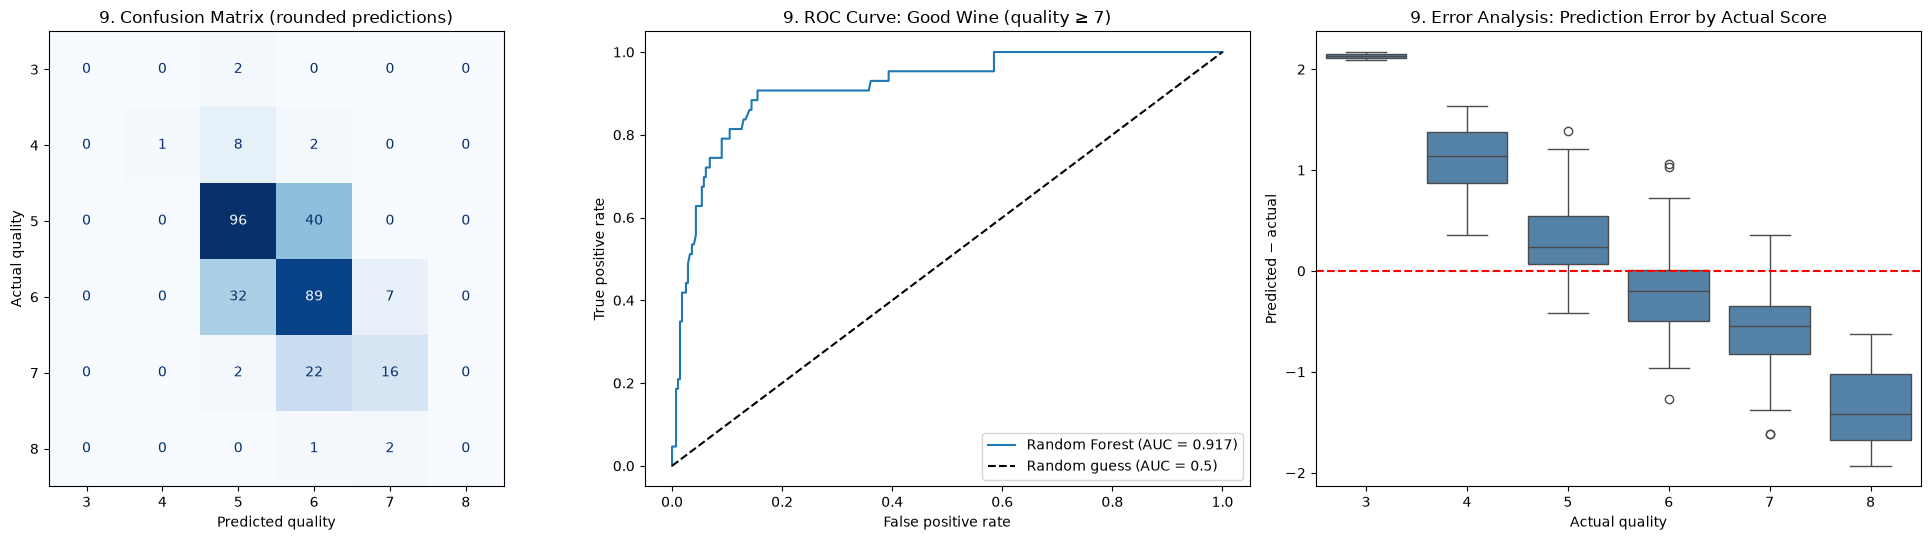

ROC AUC (good wine): 0.917
        count  mean error (bias)
actual                          
3           2               2.13
4          11               1.12
5         136               0.32
6         128              -0.21
7          40              -0.61
8           3              -1.33


In [107]:
# %% 9.3 Confusion matrix, ROC curve and error analysis
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# Confusion matrix: rows = actual score, columns = predicted score
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_class, labels=[3, 4, 5, 6, 7, 8]),
                       display_labels=[3, 4, 5, 6, 7, 8]).plot(ax=axes[0], cmap="Blues",
                                                               colorbar=False)
axes[0].set(title="9. Confusion Matrix (rounded predictions)",
            xlabel="Predicted quality", ylabel="Actual quality")

# ROC curve: how well the predicted score separates good wines (7+) from the rest
y_test_good = (y_test >= 7).astype(int)
fpr, tpr, _ = roc_curve(y_test_good, y_pred_test)
auc = roc_auc_score(y_test_good, y_pred_test)
axes[1].plot(fpr, tpr, label=f"Random Forest (AUC = {auc:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
axes[1].set(title="9. ROC Curve: Good Wine (quality ≥ 7)",
            xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend()

# Error analysis: prediction error for each actual quality score
errors = pd.DataFrame({"actual": y_test.values, "error": y_pred_test - y_test.values})
sns.boxplot(data=errors, x="actual", y="error", color="steelblue", ax=axes[2])
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set(title="9. Error Analysis: Prediction Error by Actual Score",
            xlabel="Actual quality", ylabel="Predicted − actual")
plt.tight_layout()
plt.savefig("step9_evaluation.png", dpi=110)
plt.show()

print(f"ROC AUC (good wine): {auc:.3f}")
print(errors.groupby("actual")["error"].agg(["count", "mean"]).round(2)
      .rename(columns={"mean": "mean error (bias)"}))

#### Hyperparameter Tuning

In [108]:
# %% 10.1 Complexity vs performance: validation curve for max_depth
depths = [2, 3, 4, 6, 8, 10, 12, 15, 20, None]
depth_labels = [str(d) for d in depths[:-1]] + ["None"]
tr_s, cv_s = validation_curve(
    RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    X_train, y_train, param_name="max_depth", param_range=depths,
    cv=kf, scoring="r2", n_jobs=-1)
vc = pd.DataFrame({"max_depth": depth_labels, "train_R2": tr_s.mean(axis=1),
                   "cv_R2": cv_s.mean(axis=1)})
print(vc.round(3).to_string(index=False))

max_depth  train_R2  cv_R2
        2     0.332  0.280
        3     0.422  0.319
        4     0.509  0.349
        6     0.676  0.382
        8     0.801  0.402
       10     0.871  0.413
       12     0.903  0.419
       15     0.917  0.420
       20     0.920  0.422
     None     0.920  0.422


In [109]:
# %% 10.2 Grid Search: tries every combination
param_grid = {
    "n_estimators": [200, 500],
    "max_depth": [6, 8, 12, None],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", 0.5, 1.0],
}
grid = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1),
                    param_grid, cv=kf, scoring="r2", n_jobs=-1)
grid.fit(X_train, y_train)
print(f"Grid Search - {len(grid.cv_results_['params'])} combinations")
print("Best settings:", grid.best_params_)
print(f"Best CV R2:    {grid.best_score_:.3f}")

Grid Search - 96 combinations
Best settings: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 500}
Best CV R2:    0.440


In [110]:
# %% 10.3 Random Search: samples random combinations from wider ranges
param_dist = {
    "n_estimators": randint(100, 800),
    "max_depth": [4, 6, 8, 10, 12, 16, None],
    "min_samples_leaf": randint(1, 15),
    "min_samples_split": randint(2, 20),
    "max_features": uniform(0.2, 0.8),          # fraction of features, 0.2 to 1.0
}
rand = RandomizedSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1),
                          param_dist, n_iter=40, cv=kf, scoring="r2",
                          random_state=42, n_jobs=-1)
rand.fit(X_train, y_train)
print("Random Search - 40 combinations")
print("Best settings:", {k: (round(float(v), 3) if isinstance(v, float) else v)
                         for k, v in rand.best_params_.items()})
print(f"Best CV R2:    {rand.best_score_:.3f}")

Random Search - 40 combinations
Best settings: {'max_depth': None, 'max_features': 0.598, 'min_samples_leaf': 1, 'min_samples_split': 6, 'n_estimators': 724}
Best CV R2:    0.427


In [111]:
# %% 10.4 Compare the default and tuned models
candidates = {"Default (Step 8)": rf_trained,
              "Grid Search": grid.best_estimator_,
              "Random Search": rand.best_estimator_}
rows = []
for name, model in candidates.items():
    cv = cross_val_score(model, X_train, y_train, cv=kf, scoring="r2")
    tr = regression_metrics(model, X_train, y_train)
    va = regression_metrics(model, X_val, y_val)
    rows.append({"Model": name, "CV R2": cv.mean(), "CV std": cv.std(),
                 "Train R2": tr["R2"], "Val R2": va["R2"], "Val MAE": va["MAE"],
                 "Train-Val gap": tr["R2"] - va["R2"]})
comparison = pd.DataFrame(rows).set_index("Model")
print(comparison.round(3))

                  CV R2  CV std  Train R2  Val R2  Val MAE  Train-Val gap
Model                                                                    
Default (Step 8)  0.426   0.065     0.924   0.421    0.461          0.503
Grid Search       0.440   0.048     0.926   0.430    0.455          0.496
Random Search     0.427   0.055     0.878   0.423    0.460          0.455


In [112]:
# %% 10.5 Final tuned model: retrain on train + validation, score once on test
# Choose by cross-validation R2: it averages 5 splits, so it is more reliable
# than the single 272-wine validation set
best_name = comparison["CV R2"].idxmax()
final_model = candidates[best_name]
final_model.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

final = regression_metrics(final_model, X_test, y_test)
final_class = np.clip(np.round(final_model.predict(X_test)), 3, 8).astype(int)
print(f"Final model: {best_name}")
print(f"Test R2 {final['R2']:.3f} | MAE {final['MAE']:.3f} | RMSE {final['RMSE']:.3f}")
print(f"Exact score accuracy {accuracy_score(y_test, final_class):.3f} | "
      f"weighted F1 {f1_score(y_test, final_class, average='weighted', zero_division=0):.3f}")

Final model: Grid Search
Test R2 0.511 | MAE 0.413 | RMSE 0.562
Exact score accuracy 0.691 | weighted F1 0.669


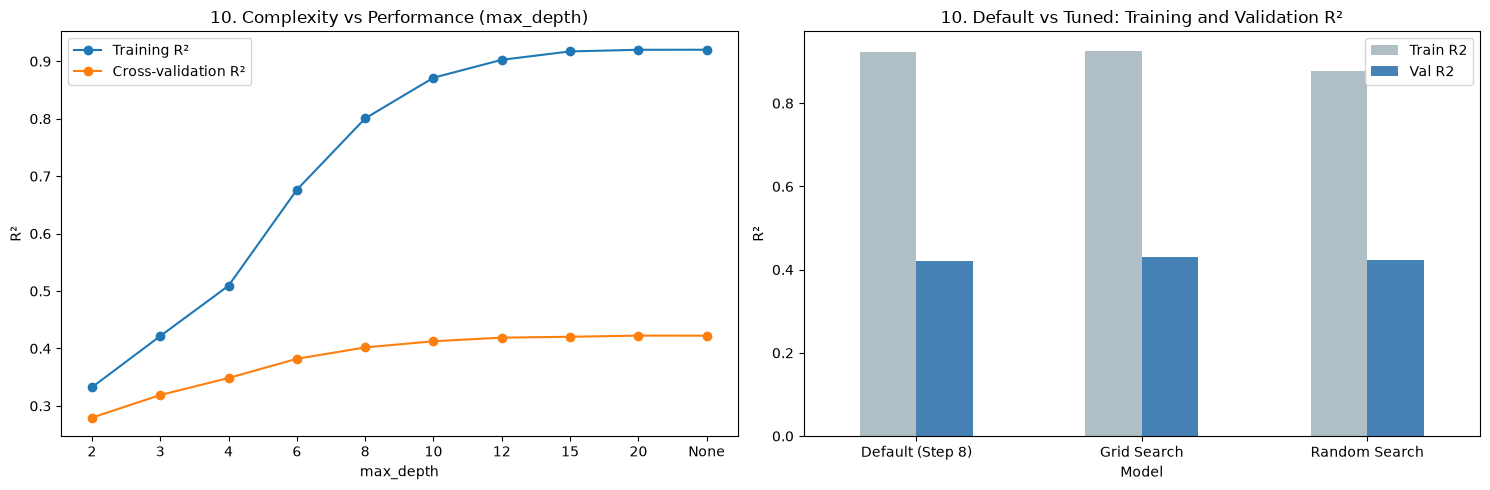

In [113]:
# %% 10.6 Plot the tuning results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(vc["max_depth"], vc["train_R2"], "o-", label="Training R²")
axes[0].plot(vc["max_depth"], vc["cv_R2"], "o-", label="Cross-validation R²")
axes[0].set(title="10. Complexity vs Performance (max_depth)",
            xlabel="max_depth", ylabel="R²")
axes[0].legend()

comparison[["Train R2", "Val R2"]].plot.bar(ax=axes[1], rot=0,
                                           color=["#b0bec5", "steelblue"])
axes[1].set(title="10. Default vs Tuned: Training and Validation R²", ylabel="R²")
plt.tight_layout()
plt.savefig("step10_tuning.png", dpi=110)
plt.show()
